# Studenten gaan geld verdienen ..
We gaan een portfolio maken via Yahoo Finance (https://finance.yahoo.com/) en de FED in St. Louis (https://fred.stlouisfed.org/categories).

In [ ]:
! pip install pandas-datareader==0.10.0
! pip install yfinance
! pip install --upgrade yfinance

import yfinance as yf
import pandas as pd
import pandas_datareader.data as web
import datetime as dt
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from datetime import date

#Clear output
from google.colab import output
output.clear()

# Aandelen, obligatie en crypto's
Alle libraries geinstalleerd, nu de data:

In [ ]:
#yf.pdr_override()

start = dt.datetime(2018,5,1)
end = dt.datetime(2024,5,1)

apple = yf.download('AAPL', start, end).tz_localize(None) # Apple
shell = yf.download('SHEL', start, end).tz_localize(None) # Shell
ng = yf.download('NOC', start, end).tz_localize(None) # Northrop Grumman
tsm = yf.download('TSM', start, end).tz_localize(None) # Taiwan Semiconductor Manufacturing Company (TSMC)
rio = yf.download('RIO', start, end).tz_localize(None) # Rio Tinto Group
ge = yf.download('GE', start, end).tz_localize(None) # General Electric Company
gs = yf.download('GS', start, end).tz_localize(None) # The Goldman Sachs Group
bond = yf.download('BOND', start, end).tz_localize(None) # PIMCO Active Bond Exchange-Traded Fund
btc = yf.download('BTC-USD', start, end).tz_localize(None) # Bitcoin USD
xrp = yf.download('XRP-USD', start, end).tz_localize(None) # XRP USD

YF.download() has changed argument auto_adjust default to True


[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed


## Portfolio

In [ ]:
portfolio = pd.concat([apple.add_suffix("_Apple"), shell.add_suffix("_Shell"), ng.add_suffix("_Northrop"),tsm.add_suffix("_TSMC"), rio.add_suffix("_RioTinto"), ge.add_suffix("_GE"), gs.add_suffix("_GoldmanSachs"), bond.add_suffix("_Bond"), btc.add_suffix("_Bitcoin"), xrp.add_suffix("_Ripple")], axis=1)
portfolio_gefilterd = portfolio.loc[:, ["Close_Apple", "Close_Shell", "Close_Northrop", "Close_TSMC","Close_RioTinto","Close_GE","Close_GoldmanSachs","Close_Bond","Close_Bitcoin","Close_Ripple"]]
portfolio_gefilterd.columns = ["Close_Apple", "Close_Shell", "Close_Northrop", "Close_TSMC","Close_RioTinto","Close_GE","Close_GoldmanSachs","Close_Bond","Close_Bitcoin","Close_Ripple"]
portfolio_gevuld = portfolio_gefilterd.ffill()
portfolio_gevuld

,Close_Apple,Close_Shell,Close_Northrop,Close_TSMC,Close_RioTinto,Close_GE,Close_GoldmanSachs,Close_Bond,Close_Bitcoin,Close_Ripple
Date,,,,,,,,,,
2018-05-01,39.899273,50.634224,273.995270,32.430233,29.978439,64.199776,201.957397,80.236755,9119.009766,0.841407
2018-05-02,41.661819,50.729553,273.941803,31.447248,30.231182,64.793770,199.721649,80.197693,9235.919922,0.859094
2018-05-03,41.737335,51.044857,281.540405,31.738798,30.472954,63.651428,199.175568,80.189880,9743.860352,0.884466
2018-05-04,43.374828,51.213528,279.908264,32.146999,30.560862,64.428230,200.481125,80.291519,9700.759766,0.895442
2018-05-05,43.374828,51.213528,279.908264,32.146999,30.560862,64.428230,200.481125,80.291519,9858.150391,0.905103
...,...,...,...,...,...,...,...,...,...,...
2024-04-26,168.504349,70.391762,472.327148,136.391861,63.981560,161.272705,418.341400,84.749924,63755.320312,0.526112
2024-04-27,168.504349,70.391762,472.327148,136.391861,63.981560,161.272705,418.341400,84.749924,63419.140625,0.517775
2024-04-28,168.504349,70.391762,472.327148,136.391861,63.981560,161.272705,418.341400,84.749924,63113.230469,0.510377


# Grondstoffen
https://tradingeconomics.com/commodities

In [ ]:
graan = web.get_data_fred('PWHEAMTUSDM', start, end) #graan
hout = web.get_data_fred('WPU08', start, end) #hout
katoen = web.get_data_fred('PCOTTINDUSDM', start, end) #katoen
koffie = web.get_data_fred('WPU026301', start, end) #koffiebonen
rubber = web.get_data_fred('PRUBBUSDM', start, end) #rubber
vlees = web.get_data_fred('PBEEFUSDM', start, end) #vleesprijs
wol = web.get_data_fred('PWOOLFUSDM', start, end) #wol
zonnebloem = web.get_data_fred('PSUNOUSDM', start, end) #zonnebloemolie

gas = web.get_data_fred('GASREGW', start, end) #gas (US Regular All Formulations Gas Price)
kolen = web.get_data_fred('WPU058103', start, end) #kolen (Producer Price Index by Commodity: Fuels and Related Products and Power: Other Petroleum and Coal Products, Including Coke Oven Products, Not Elsewhere Classified)
oil = yf.download('CL=F', start, end).tz_localize(None) #olie
uranium = web.get_data_fred('PURANUSDM', start, end) #uranium

goud = yf.download('GC=F', start, end).tz_localize(None) #goud future
koper = web.get_data_fred('PCOPPUSDM', start, end) #koperprijs
palladium = yf.download('PA=F', start, end).tz_localize(None) #palladium
staal = web.get_data_fred('WPU101707', start, end) #staal (Producer Price Index by Commodity: Metals and Metal Products: Cold Rolled Steel Sheet and Strip )
zilver = yf.download('SI=F', start, end).tz_localize(None) #zilver future

#kobalt
#silicium

[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed


Sowieso toe te voegen aan deze tabellen: is dit een prijs per dag? In welke eenheid? Per m3 of liter of vat of ..

## Portfolio

In [ ]:
grondstoffen_1 = pd.concat([graan, koffie, vlees, gas, kolen], axis=1)
grondstoffen_1.columns = ["Graan", "Koffie", "Vlees", "Gas", "Kolen"]
grondstoffen_1

,Graan,Koffie,Vlees,Gas,Kolen
DATE,,,,,
2018-05-01,192.70383,194.200,188.000000,NaN,595.400
2018-05-07,NaN,NaN,NaN,2.845,NaN
2018-05-14,NaN,NaN,NaN,2.873,NaN
2018-05-21,NaN,NaN,NaN,2.923,NaN
2018-05-28,NaN,NaN,NaN,2.962,NaN
...,...,...,...,...,...
2024-04-08,NaN,NaN,NaN,3.591,NaN
2024-04-15,NaN,NaN,NaN,3.628,NaN
2024-04-22,NaN,NaN,NaN,3.668,NaN


In [ ]:
grondstoffen_2 = pd.concat([oil.add_suffix("_Olie"), goud.add_suffix("_Goud"), palladium.add_suffix("_Palladium")], axis = 1)
grondstoffen_2 = grondstoffen_2.loc[:, ["Close_Olie", "Close_Goud", "Close_Palladium"]]
grondstoffen_2.columns = ["Olie", "Goud", "Palladium"]
grondstoffen_2

,Olie,Goud,Palladium
Date,,,
2018-05-01,67.250000,1303.800049,938.450012
2018-05-02,67.930000,1302.599976,962.349976
2018-05-03,68.430000,1310.699951,960.900024
2018-05-04,69.720001,1312.699951,959.450012
2018-05-07,70.730003,1312.199951,964.299988
...,...,...,...
2024-04-24,82.809998,2324.500000,1007.400024
2024-04-25,83.570000,2329.800049,981.099976
2024-04-26,83.849998,2334.800049,957.400024


In [ ]:
grondstoffen_portfolio = pd.concat([grondstoffen_1, grondstoffen_2], axis=1)
grondstoffen_portfolio = grondstoffen_portfolio.ffill()
grondstoffen_portfolio

,Graan,Koffie,Vlees,Gas,Kolen,Olie,Goud,Palladium
2018-05-01,192.703830,194.200,188.000000,NaN,595.400,67.250000,1303.800049,938.450012
2018-05-02,192.703830,194.200,188.000000,NaN,595.400,67.930000,1302.599976,962.349976
2018-05-03,192.703830,194.200,188.000000,NaN,595.400,68.430000,1310.699951,960.900024
2018-05-04,192.703830,194.200,188.000000,NaN,595.400,69.720001,1312.699951,959.450012
2018-05-07,192.703830,194.200,188.000000,2.845,595.400,70.730003,1312.199951,964.299988
...,...,...,...,...,...,...,...,...
2024-04-25,208.381685,253.486,270.568182,3.668,638.273,83.570000,2329.800049,981.099976
2024-04-26,208.381685,253.486,270.568182,3.668,638.273,83.849998,2334.800049,957.400024
2024-04-29,208.381685,253.486,270.568182,3.653,638.273,82.629997,2345.399902,976.700012
2024-04-30,208.381685,253.486,270.568182,3.653,638.273,81.930000,2291.399902,951.900024


# Hoe kun je de portfolio- en de grondstoffendata samenvoegen?
Via een concat:

In [ ]:
portfolio_compleet = pd.concat([portfolio_gevuld, grondstoffen_portfolio], axis=1)
portfolio_compleet = portfolio_compleet.ffill()
portfolio_compleet = portfolio_compleet.loc[portfolio_compleet.loc[:, "Gas"] > 0, :]
portfolio_compleet

,Close_Apple,Close_Shell,Close_Northrop,Close_TSMC,Close_RioTinto,Close_GE,Close_GoldmanSachs,Close_Bond,Close_Bitcoin,Close_Ripple,Graan,Koffie,Vlees,Gas,Kolen,Olie,Goud,Palladium
2018-05-07,43.688652,51.132881,282.833557,32.030376,30.483940,64.291161,202.409637,80.299362,9373.009766,0.832641,192.703830,194.200,188.000000,2.845,595.400,70.730003,1312.199951,964.299988
2018-05-08,43.898643,51.352856,293.660614,32.638496,30.445477,65.205017,202.238983,80.197693,9234.820312,0.813970,192.703830,194.200,188.000000,2.845,595.400,69.059998,1312.000000,965.599976
2018-05-09,44.207737,52.584797,292.162323,32.780102,31.077358,66.804321,206.275238,80.080444,9325.179688,0.802043,192.703830,194.200,188.000000,2.845,595.400,71.139999,1311.300049,972.799988
2018-05-10,44.840084,52.778004,291.109955,33.129990,31.511427,67.124161,207.734451,80.174255,9043.940430,0.758237,192.703830,194.200,188.000000,2.845,595.400,71.360001,1320.800049,996.099976
2018-05-11,44.669548,53.491314,290.119934,33.246616,31.533401,66.712929,207.290695,80.275887,8441.490234,0.684948,192.703830,194.200,188.000000,2.845,595.400,70.699997,1319.000000,987.400024
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2024-04-27,168.504349,70.391762,472.327148,136.391861,63.981560,161.272705,418.341400,84.749924,63419.140625,0.517775,208.381685,253.486,270.568182,3.668,638.273,83.849998,2334.800049,957.400024
2024-04-28,168.504349,70.391762,472.327148,136.391861,63.981560,161.272705,418.341400,84.749924,63113.230469,0.510377,208.381685,253.486,270.568182,3.668,638.273,83.849998,2334.800049,957.400024
2024-04-29,172.684601,70.247658,477.999634,136.589111,64.703506,163.398483,421.511475,85.082748,63841.121094,0.515432,208.381685,253.486,270.568182,3.653,638.273,82.629997,2345.399902,976.700012
2024-04-30,169.529510,68.845009,476.829742,135.445099,63.597149,160.746201,417.499969,84.806969,60636.855469,0.500065,208.381685,253.486,270.568182,3.653,638.273,81.930000,2291.399902,951.900024


# Data naar Excel exporteren
Als je data naar Excel wilt exporteren, gebruik dan onderstaand commando:

In [ ]:
portfolio_compleet.to_excel('portfolio.xlsx', index=True)

# Data uit Excel importeren
Als je data uit Excel wilt importeren, gebruik dan onderstaand commando:

In [ ]:
portfolio_excel = pd.read_excel("portfolio.xlsx", sheet_name="portfolio")

portfolio_excel

Let Op: het bestand dat je exporteert of wilt importeren, komt te staan / moet staan in de map ' content':<br>
zie menu helemaal links, klik op het onderste ' Bestanden'-icoontje en kijk in de map ' content'.

# Correlatiematrix (heatmap)
Correlatie geeft de mate van samenhang tussen twee variabelen weer, ofwel in hoeverre twee variabelen elkaar beïnvloeden. De correlatie wordt uitgedrukt in de correlatiecoëfficiënt. De waarde van de correlatiecoëfficiënt ligt altijd tussen -1 en +1.
<p>
Als de correlatiecoëfficiënt ligt tussen de -0,3 en 0,3 is er geen sprake van correlatie.<br>
Als de correlatiecoëfficiënt ligt tussen de (-0,3 -0,6) of (0,3 0,6) is er sprake van zwakke correlatie.<br>
Als de correlatiecoëfficiënt ligt tussen de (-0,6 -0,9) of (0,6 0,9) is er sprake van matige correlatie.<br>
Als de correlatiecoëfficiënt ligt tussen de (-0,9 -1) of (0,9 1) is er sprake van sterke correlatie.<br>

<Axes: >

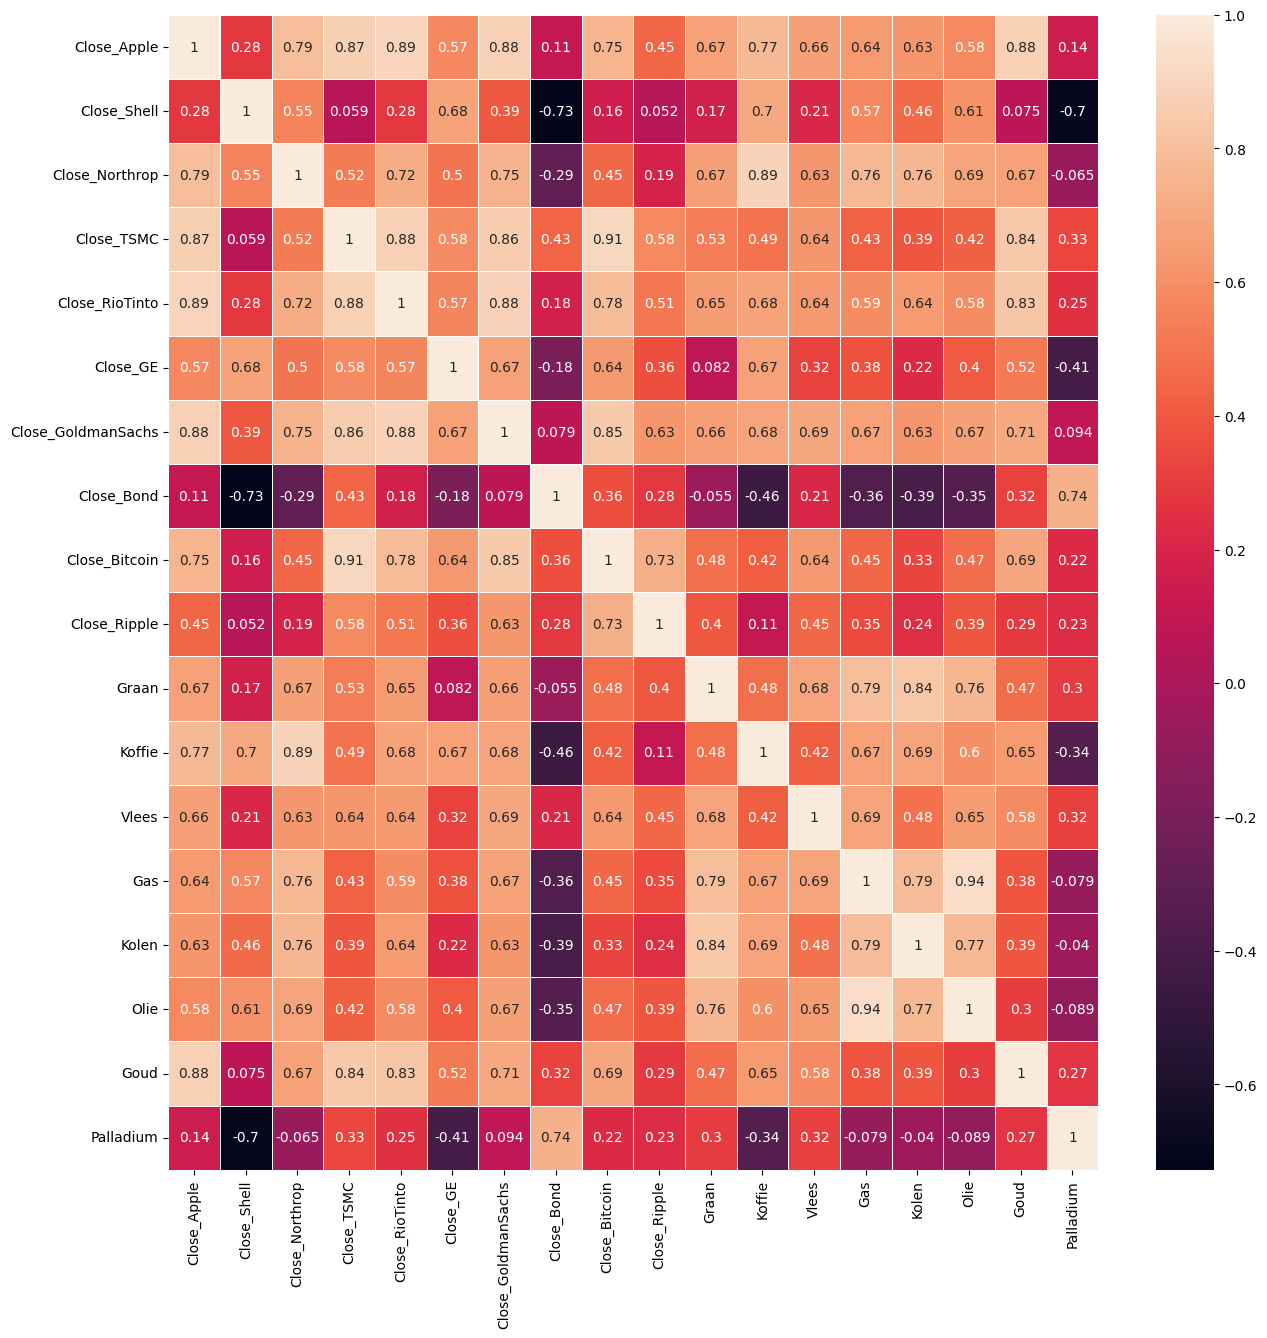

In [ ]:
import seaborn as sns

fig, ax = plt.subplots(figsize=(15,15))         # Sample figsize in inches
sns.heatmap(portfolio_compleet.corr(),annot=True, linewidths=.5, ax=ax)

Conclusie? Welke opvallende verbanden zien we in de data?

# Enkelvoudige lineaire regressie met kwantitatieve data
Eerst lezen we de benodigde libraries voor de regressie-analyse in:

In [ ]:
import statsmodels.api as sm
import numpy as np

from scipy import stats
from sklearn.linear_model import LinearRegression

Daarna kiezen we de x en y variabelen op basis van de zelf opgestelde hypothese:<br>
- x: de oorzaak of verklarende variabele<br>
- y: het gevolg of de te verklaren variabele

In [ ]:
X = portfolio_compleet[["Goud"]]
y = portfolio_compleet[["Close_Apple"]]

X2 = sm.add_constant(X)
est = sm.OLS(y, X2)
est2 = est.fit()
print(est2.summary())

                            OLS Regression Results                            
Dep. Variable:            Close_Apple   R-squared:                       0.770
Model:                            OLS   Adj. R-squared:                  0.769
Method:                 Least Squares   F-statistic:                     7295.
Date:                Fri, 25 Apr 2025   Prob (F-statistic):               0.00
Time:                        11:11:41   Log-Likelihood:                -10084.
No. Observations:                2187   AIC:                         2.017e+04
Df Residuals:                    2185   BIC:                         2.018e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const       -166.4634      3.347    -49.731      0.0

We onderzoeken of er een verband is tussen de koers van Apple en goud. Het model is:<br>
koers Apple = -166,46 + 0,165 x koers van goud<br>
<p>
Er lijkt een positief verband te zijn tussen de koers van Apple en goud: hoe hoger de goudkoers, hoe hoger de koers van Apple.<br>
<p>
Is het model geldig?<br>
De p-waarde van de variabele 'slotkoers goud' is kleiner dan 0,05, dat is ok.<br>
De R-kwadraat waarde is 0,769: er is een matig (statistisch) verband in deze dataset tussen de koers van Apple en goud.

## Intermezzo: wat staat er allemaal bij de OLS Regression Results?
**Aan de linkerkant:**<br>
Dep.Variable = de afhankelijke variabele<br>
Model = welk type regressie-model wordt er gebruikt, hier: Ordinary Least Squares<br>
Method = welke methode wordt gebruikt voor het schatten van de regressie-lijn<br>
No. Observations = steekproefgrootte (of aantal datapunten of regels van het dataframe)<br>
Df Residuals = Degree of freedom is the number of independent observations on the basis of which the sum of squares is calculated. Te berekenen door: Degrees of freedom (Df)  = N – K<br>
N = sample size (no. of observations) and  K = number of variables + 1<br>
Df Model = Degrees of freedom van het model = K - 1<br>
Covariance Type = robust of nonrobust, maar wat dat precies betekent?<br>
https://en.wikipedia.org/wiki/Heteroskedasticity-consistent_standard_errors
<br>
<br>
**Aan de rechterkant:**<br>
R-squared = de determinatiecoefficient, hoeveel % van de variatie in de y-variabele (gevolg) wordt verklaard door de x-variabele(n)(oorza(a)k(en))<br>
Adj. R-squared = te gebruiken bij meervoudige regressie, om te kijken of alle x-en bijdragen aan het verklaren van de variatie in y.<br>
F-statistic =  F test tells the goodness of fit of a regression. The test is similar to the t-test or other tests for the hypothesis.<br>
Prob (F-statistic) =  de kans op een uitkomst gelijk aan of groter dan de F-statistic. Als deze kans erg klein is, verwerpen we de Ho-hypothese dat de coefficienten gelijk zijn aan 0 (vergelijkbaar met de t-test en de p-waarden).<br>
Log-Likelihood =  een maatstaf voor hoe waarschijnlijk het is dat de steekproefdata hoort bij het gevonden regressiemodel.<br>
Bayes: P(data | model).<br>
https://en.wikipedia.org/wiki/Likelihood_function#Log-likelihood<br>
AIC = the [Akaike Information Criteria (AIC) ](https://en.wikipedia.org/wiki/Akaike_information_criterion) is an estimator of prediction error and thereby relative quality of statistical models for a given set of data. Given a collection of models for the data, AIC estimates the quality of each model, relative to each of the other models. Thus, AIC provides a means for model selection. The lower, the better.<br>
BIC = the [Bayesian Information Criterion (BIC)](https://en.wikipedia.org/wiki/Bayesian_information_criterion) or Schwarz information criterion (also SIC, SBC, SBIC) is a criterion for model selection among a finite set of models; models with lower BIC are generally preferred. It is based, in part, on the likelihood function and it is closely related to the Akaike information criterion (AIC).
<br>
<br>
**In het midden:**<br>
coef = de coefficienten van de regressielijn. Bij een enkelvoudige regressie y = ax + b is 'const' de constante b en a het getal dat staat bij de onafhankelijke variabele x.<br>
std err = de standaardafwijking van de coefficienten.<br>
t = de t-waarde van de t-test op de coefficienten, waarbij de Ho-hypothese is dat de coefficient een waarde van 0 heeft.<br>
P>|t| = de kans op een uitkomst groter of gelijk aan de t-waarde. Dit noemen we de p-waarde, om een regressiemodel geldig te laten zijn, mag deze niet groter zijn dan 0,05.<br>
[0.025      0.975] = 95%-betrouwbaarheidsinterval voor de coefficienten.<br>
<br>
**Onder:**<br>
Omnibus = describes the normalcy of the distribution of our residuals using skew and kurtosis as measurements. A 0 would indicate perfect normalcy.<br>
Prob(Omnibus) = is a statistical test measuring the probability the residuals are normally distributed. A 1 would indicate perfectly normal distribution.<br>
Skew = is a measurement of symmetry in our data, with 0 being perfect symmetry.<br>
Kurtosis = measures the peakiness of our data, or its concentration around 0 in a normal curve. A kurtosis of 3 implies a normal distribution. Higher kurtosis implies fewer outliers.<br>
<br>
Durbin-Watson = the [Durbin Watson (DW) statistic](https://www.investopedia.com/terms/d/durbin-watson-statistic.asp) is a test for autocorrelation in the residuals from a statistical model or regression analysis. The Durbin-Watson statistic will always have a value ranging between 0 and 4. A value of 2.0 indicates there is no autocorrelation detected in the sample. Values from 0 to less than 2 point to positive autocorrelation and values from 2 to 4 means negative autocorrelation.<br>
Jarque-Bera (JB) = the [Jarque–Bera test](https://en.wikipedia.org/wiki/Jarque%E2%80%93Bera_test) is a goodness-of-fit test of whether sample data have the skewness and kurtosis matching a normal distribution. The test is named after Carlos Jarque and Anil K. Bera. The test statistic is always nonnegative. If it is far from zero, it signals the data do not have a normal distribution.<br>
Prob(JB) = de kans op een uitkomst groter of gelijk aan de JB-testwaarde. Als deze kans erg klein is, verwerpen we de Ho-hypothese dat de data normaal verdeeld zijn.<br>
Cond. No. = is a measurement of the sensitivity of our model as compared to the size of changes in the data it is analyzing. Multicollinearity is strongly implied by a high condition number.
Multicollinearity = a term to describe two or more independent variables that are strongly related to each other and are falsely affecting our predicted variable by redundancy.<br>
<br>
Bronnen:<br>
https://medium.com/swlh/interpreting-linear-regression-through-statsmodels-summary-4796d359035a<br>
https://jyotiyadav99111.medium.com/statistics-how-should-i-interpret-results-of-ols-3bde1ebeec01

# Meervoudige lineaire regressie
Kunnen we de regressie ook met meerdere onafhankelijke variabelen doen?<br>
Jazeker, dat heet meervoudige regressie:

In [ ]:
X = portfolio_compleet[["Goud", "Palladium"]]
y = portfolio_compleet[["Close_TSMC"]]

X2 = sm.add_constant(X)
est = sm.OLS(y, X2)
est2 = est.fit()
print(est2.summary())

                            OLS Regression Results                            
Dep. Variable:             Close_TSMC   R-squared:                       0.725
Model:                            OLS   Adj. R-squared:                  0.725
Method:                 Least Squares   F-statistic:                     2879.
Date:                Fri, 25 Apr 2025   Prob (F-statistic):               0.00
Time:                        11:12:50   Log-Likelihood:                -9219.6
No. Observations:                2187   AIC:                         1.845e+04
Df Residuals:                    2184   BIC:                         1.846e+04
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const        -97.1154      2.322    -41.818      0.0

Conclusie?